## Attention

编码器-解码器架构十分有趣，但它存在一个瓶颈：整个源序列仅由一个隐藏状态，即编码器部分的最终隐藏状态来表示。即便对于像我们所用的这种很短的源序列，要让解码器仅凭如此少量的信息生成目标序列，也是一项不小的挑战。

如果解码器可以选择编码器的一个（或多个）隐藏状态来使用，而不是只能使用最后一个隐藏状态，会怎么样？这无疑能让解码器在目标序列生成的每一步，更灵活地选用更有用的隐藏状态。

**解码器不再仅依靠自身生成预测结果，而是会调用注意力机制，以此帮助判断需要关注源序列中的哪些部分。**

## Values

从现在起，我们将编码器的（所有）隐藏状态（或其仿射变换）称为**Values**（V）。将一个“Values”与其对应的注意力分数相乘得到的结果称为对齐向量。所有对齐向量的总和（即隐藏状态的加权平均值）被称为上下文向量。

![](../pictures/attention0.png)


##  where do the attention scores come from?
## "Keys" and "Queries"

### **注意力分数**是通过将解码器的**每个隐藏状态（h2）** 与编码器的**所有**隐藏状态（h0和h1）进行匹配得到的。其中部分匹配效果较好（注意力分数高），另一部分匹配效果较差（注意力分数低）。

解码器的隐藏状态、编码器的隐藏状态分别被称为**查询（Q）**、**键（K）**
编码器的隐藏状态同时用作“键”（K）和“值”（V）。后续我们会对隐藏状态施加仿射变换，一组变换用于生成“键”，另一组用于生成“值”，因此二者最终的取值实际上并不相同。

简单来说，编码器的工作原理类似于键值存储，就好比某种数据库，随后解码器会向其发起查询。注意力机制会根据查询去检索对应的键（即匹配环节），并返回对应的值。该机制返回的并不是单个原始值，而是所有值的加权平均值。

![](../pictures/attention1.png)

In [2]:
import numpy as np
import torch
from matplotlib import pyplot as plt
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from train import train


In [3]:
class Attention(nn.Module):
    def __init__(self, hidden_dim, input_dim=None, proj_values=False):
        super().__init__()
        self.d_k = hidden_dim
        self.input_dim = hidden_dim if input_dim is None else input_dim
        # Affine transformations for value, if proj_values is True
        self.proj_values = proj_values
        # Affine transformations for Q,K, and V
        self.linear_query = nn.Linear(self.input_dim, hidden_dim)
        self.linear_key = nn.Linear(self.input_dim, hidden_dim)
        self.linear_value = nn.Linear(self.input_dim, hidden_dim)
        self.alphas: torch.Tensor
        self.keys: torch.Tensor
        self.values: torch.Tensor

    def init_keys(self, keys):
        self.keys = keys
        self.proj_keys = self.linear_key(self.keys)
        self.values = self.linear_value(self.keys) if self.proj_values else self.keys

    def score_function(self, query):
        proj_query = self.linear_query(query)
        dot_products = torch.bmm(proj_query, self.proj_keys.permute(0, 2, 1))
        scores = dot_products / np.sqrt(self.d_k)
        return scores

    def forward(self, query, mask=None):
        # Query is batch-first N, 1, H
        scores = self.score_function(query)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        alphas = F.softmax(scores, dim=-1)
        self.alphas = alphas.detach()

        context = torch.bmm(alphas, self.values)
        return context


In [4]:
class DecoderAttn(nn.Module):
    def __init__(self, n_features, hidden_dim) -> None:
        super().__init__()
        self.hidden_dim = hidden_dim
        self.n_features = n_features
        self.hidden = None
        self.basic_rnn = nn.GRU(self.n_features, self.hidden_dim, batch_first=True)
        self.attn = Attention(self.hidden_dim)
        self.regression = nn.Linear(2 * self.hidden_dim, self.n_features)

    def init_hidden(self, hidden_seq):
        # the output of the encoder is N, L, H
        # and init_keys expects batch-first as well
        self.attn.init_keys(hidden_seq)
        hidden_final = hidden_seq[:, -1:]
        self.hidden = hidden_final.permute(1, 0, 2)

    def forward(self, X, mask=None):
        # X is N,1,F
        batch_first_output, self.hidden = self.basic_rnn(X, self.hidden)
        query = batch_first_output[:, -1:]
        # Attention
        context = self.attn(query, mask=mask)
        concatenated = torch.cat([context, query], axis=-1)
        out = self.regression(concatenated)

        return out.view(-1, 1, self.n_features)


In [5]:
class Encoder(nn.Module):
    def __init__(self, n_features, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.n_features = n_features
        self.hidden = None
        self.basic_rnn = nn.GRU(self.n_features, self.hidden_dim, batch_first=True)

    def forward(self, X):
        rnn_out, self.hidden = self.basic_rnn(X)
        return rnn_out


In [6]:
class EncoderDecoder(nn.Module):
    def __init__(
        self, encoder, decoder, input_len, target_len, teacher_forcing_prob=0.5
    ) -> None:
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.input_len = input_len
        self.target_len = target_len
        self.teacher_forcing_prob = teacher_forcing_prob
        self.outputs: torch.Tensor  # Note: no initial value

    def init_outputs(self, batch_size):
        device = next(self.parameters()).device
        self.outputs = torch.zeros(
            batch_size, self.target_len, self.encoder.n_features
        ).to(device)

    def store_output(self, i, out):
        self.outputs[:, i : i + 1, :] = out

    def forward(self, X):
        # splits the data in source and target sequences
        # the target seq will be empty in testing mode
        # N, L, F
        source_seq = X[:, : self.input_len, :]
        target_seq = X[:, self.input_len :, :]
        self.init_outputs(X.shape[0])

        # Encoder expected N, L, F
        hidden_seq = self.encoder(source_seq)
        # Output is N, L, H
        self.decoder.init_hidden(hidden_seq)

        # The last input of the encoder is also
        # the first input of the decoder

        dec_inputs = source_seq[:, -1:, :]

        # Generates as many outputs as the target length
        for i in range(self.target_len):
            # Output of decoder is N, 1, F
            out = self.decoder(dec_inputs)
            self.store_output(i, out)

            prob = self.teacher_forcing_prob
            # In evaluation / test the target sequence is
            # unknown, so we cannot use teacher forcing

            if not self.training:
                prob = 0

            if torch.rand(1) < prob:
                # Takes the actual element
                dec_inputs = target_seq[:, i : i + 1, :]
            else:
                # Otherwise uses the last predicted output
                dec_inputs = out

        return self.outputs


In [7]:
class EncoderDecoderAttn(EncoderDecoder):
    def __init__(
        self, encoder, decoder, input_len, target_len, teacher_forcing_prob=0.5
    ) -> None:
        super().__init__(encoder, decoder, input_len, target_len, teacher_forcing_prob)
        self.alphas: torch.Tensor  # Note: no initial value

    def init_outputs(self, batch_size):
        device = next(self.parameters()).device
        # N, L(target),F
        self.outputs = torch.zeros(
            batch_size, self.target_len, self.encoder.n_features
        ).to(device)

        # N,L(target),L(source)
        self.alphas = torch.zeros(batch_size, self.target_len, self.input_len).to(
            device
        )

    def store_output(self, i, out):
        # store the output
        self.outputs[:, i : i + 1, :] = out
        self.alphas[:, i : i + 1, :] = self.decoder.attn.alphas


In [8]:
def generate_sequences(n=128, variable_len=False, seed=13):
    """随机生成 n 组沿着正方形轮廓游走的坐标序列，每条序列随机选择起点、
    正向 / 反向绕行；可选固定长度或随机长度，叠加微小噪声；
    标签就是绕行方向，用来做序列分类训练。"""

    basic_corners = np.array([[-1, -1], [-1, 1], [1, 1], [1, -1]])
    # 创建独立随机数生成器
    rng = np.random.default_rng(seed)
    bases = rng.integers(4, size=n)
    if variable_len:
        # 3个可选值：0,1,2 → +2 → 2,3,4
        lengths = rng.integers(3, size=n) + 2
    else:
        lengths = [4] * n

    directions = rng.integers(2, size=n)

    points = [
        basic_corners[[(b + i) % 4 for i in range(4)]][slice(None, None, d * 2 - 1)][:l]
        + rng.standard_normal((l, 2)) * 0.1
        for b, d, l in zip(bases, directions, lengths)
    ]
    return np.array(points), np.array(directions)


In [9]:
# Data Generation -- Train
points, directions = generate_sequences(n=256, seed=13)
full_train = torch.as_tensor(points).float()
target_train = full_train[:, 2:]

# Data Generation -- Test
test_points, test_directions = generate_sequences(seed=19)
full_test = torch.as_tensor(test_points).float()
source_test = full_test[:, :2]
target_test = full_test[:, 2:]

train_data = TensorDataset(full_train, target_train)
test_data = TensorDataset(full_test, target_test)
generator = torch.Generator()
train_loader = DataLoader(train_data, batch_size=16, shuffle=True, generator=generator)
test_loader = DataLoader(test_data, batch_size=16)


In [10]:
torch.manual_seed(23)
encoder = Encoder(n_features=2, hidden_dim=2)
decoder_attn = DecoderAttn(n_features=2, hidden_dim=2)
model = EncoderDecoderAttn(
    encoder, decoder_attn, input_len=2, target_len=2, teacher_forcing_prob=0.5
)
loss = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)


In [11]:
train_losses, test_losses = train(
    model, train_loader, test_loader, loss, optimizer, 100
)


Epoch 1/100 - loss: 1.0079 - val_loss: 0.9257
Epoch 2/100 - loss: 0.8617 - val_loss: 0.7868
Epoch 3/100 - loss: 0.7119 - val_loss: 0.6413
Epoch 4/100 - loss: 0.5899 - val_loss: 0.5369
Epoch 5/100 - loss: 0.5348 - val_loss: 0.5144
Epoch 6/100 - loss: 0.5244 - val_loss: 0.5090
Epoch 7/100 - loss: 0.5170 - val_loss: 0.5083
Epoch 8/100 - loss: 0.5149 - val_loss: 0.5066
Epoch 9/100 - loss: 0.5092 - val_loss: 0.5049
Epoch 10/100 - loss: 0.5075 - val_loss: 0.5022
Epoch 11/100 - loss: 0.4976 - val_loss: 0.4962
Epoch 12/100 - loss: 0.4962 - val_loss: 0.4856
Epoch 13/100 - loss: 0.4815 - val_loss: 0.4658
Epoch 14/100 - loss: 0.4634 - val_loss: 0.4401
Epoch 15/100 - loss: 0.4281 - val_loss: 0.4101
Epoch 16/100 - loss: 0.4087 - val_loss: 0.3888
Epoch 17/100 - loss: 0.3864 - val_loss: 0.3765
Epoch 18/100 - loss: 0.3720 - val_loss: 0.3561
Epoch 19/100 - loss: 0.3479 - val_loss: 0.3396
Epoch 20/100 - loss: 0.3267 - val_loss: 0.3221
Epoch 21/100 - loss: 0.3050 - val_loss: 0.2886
Epoch 22/100 - loss: 0

In [ ]:
def sequence_pred(model, X, directions=None, n_rows=2, n_cols=5):
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axs = axs.flatten()

    for e, ax in enumerate(axs):
        first_corners = X[e, :2, :]
        model.eval()
        next_corners = (
            model(X[e : e + 1, :2].to(X.device)).squeeze().detach().cpu().numpy()
        )
        pred_corners = np.concatenate([first_corners, next_corners], axis=0)

        for j, corners in enumerate([X[e], pred_corners]):
            for i in range(4):
                coords = corners[i]
                color = "k"
                ax.scatter(*coords, c=color, s=400)
                if i == 3:
                    start = -1
                else:
                    start = i
                if (not j) or (j and i):
                    ax.plot(
                        *corners[[start, start + 1]].T,
                        c="k",
                        lw=2,
                        alpha=0.5,
                        linestyle="--" if j else "-",
                    )
                ax.text(
                    *(coords - np.array([0.04, 0.04])), str(i + 1), c="w", fontsize=12
                )
                if directions is not None:
                    ax.set_title(f"{'Counter-' if not directions[e] else ''}Clockwise")

        ax.set_xlabel(r"$x_0$")
        ax.set_ylabel(r"$x_1$", rotation=0)
        ax.set_xlim([-1.45, 1.45])
        ax.set_ylim([-1.45, 1.45])

    fig.tight_layout()
    return fig


C:\Users\cuish\AppData\Local\Temp\ipykernel_25868\230445282.py:35: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  *(coords - np.array([0.04, 0.04])), str(i + 1), c="w", fontsize=12


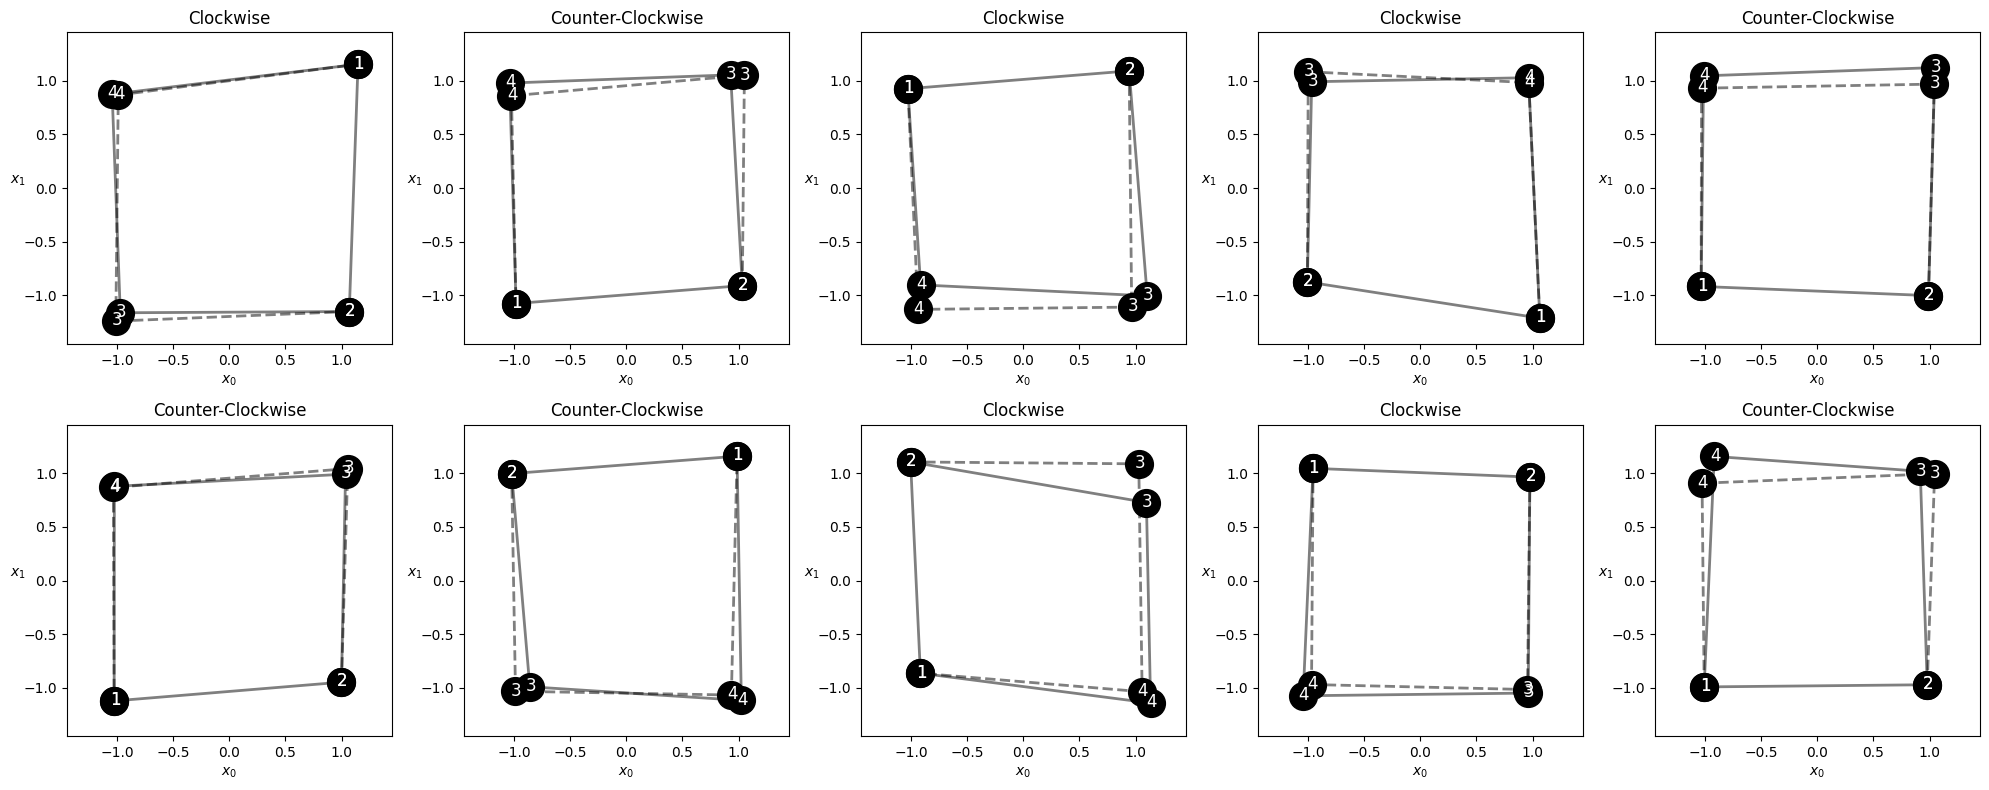

: 

In [ ]:
fig = sequence_pred(model, full_test, directions=test_directions)